# Modelado y Evaluación de un Modelo de Churn

**Curso:** Data Science II — Coderhouse

**Problema:** predecir el **abandono de clientes (churn)** de una empresa de
telecomunicaciones a partir de sus características de contrato y consumo. Es un problema de
**clasificación binaria** (`Churn` = Yes/No).

**Dataset:** *Telco Customer Churn* (IBM Sample Data), descargado de Kaggle
(`blastchar/telco-customer-churn`). 7.043 clientes, 21 columnas. El objetivo del negocio
es **detectar a tiempo a los clientes en riesgo** para accionar retención.

> Colocar el archivo descargado como `telco_churn.csv` (junto al notebook)
> y ajustar la ruta `CSV` si lo guardás en otro lado.


## 1. Carga de datos

In [1]:
import pandas as pd

CSV = "telco_churn.csv"
df = pd.read_csv(CSV)
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Limpieza

Dos ajustes típicos de este dataset:
- **`TotalCharges`** se lee como texto porque 11 registros (clientes con `tenure` = 0)
  tienen el valor en blanco. Se convierte a numérico; los blancos quedan como nulos y se
  imputarán dentro del pipeline.
- **`customerID`** es un identificador único: se descarta (no aporta y provocaría overfit).
- **`Churn`** (Yes/No) se convierte al target binario `churn` (1/0).


In [2]:
# TotalCharges a numérico (los blancos -> NaN)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Descartar identificador
df = df.drop(columns=["customerID"])

# Target binario
df["churn"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns=["Churn"])

print("Nulos en TotalCharges:", int(df["TotalCharges"].isna().sum()))
print("Tasa de churn:", round(df["churn"].mean(), 3))

Nulos en TotalCharges: 11
Tasa de churn: 0.265


## 3. Definición de variables y división Train/Test (80/20)

Se identifican columnas numéricas y categóricas automáticamente, y se separa **antes** de
entrenar, estratificando por la clase.


In [3]:
from sklearn.model_selection import train_test_split

num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat_cols = [c for c in df.columns if c not in num_cols + ["churn"]]
print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

X = df.drop(columns=["churn"])
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nTrain:", X_train.shape, "| Test:", X_test.shape)

Numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
Categóricas: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Train: (5634, 19) | Test: (1409, 19)


## 4. Preprocesamiento + modelo (Random Forest)

Preprocesamiento (imputación, escalado y One-Hot) y modelo encapsulados en un `Pipeline`
para evitar data leakage y mantener consistencia train/inferencia.


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

preprocesador = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

modelo = Pipeline([
    ("prep", preprocesador),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=42)),
])
modelo.fit(X_train, y_train)
print("Modelo entrenado.")

Modelo entrenado.


## 5. Evaluación de métricas (set de prueba)

Accuracy, Precision, Recall y F1 sobre la **clase positiva (churn = 1)**.


In [5]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report)

y_pred = modelo.predict(X_test)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred):.3f}")
print(f"F1-Score : {f1_score(y_test, y_pred):.3f}")
print("\n", classification_report(y_test, y_pred, target_names=["No churn", "Churn"]))

Accuracy : 0.779
Precision: 0.608
Recall   : 0.476
F1-Score : 0.534

               precision    recall  f1-score   support

    No churn       0.82      0.89      0.86      1035
       Churn       0.61      0.48      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409



## 6. Matriz de confusión (heatmap)

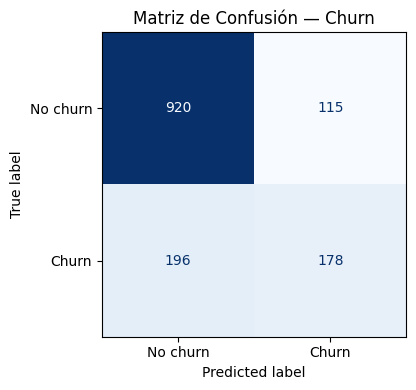

Verdaderos negativos : 920
Falsos positivos     : 115
Falsos negativos (FN): 196  <- clientes que SE VAN y el modelo no detecta
Verdaderos positivos : 178


In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(
    cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Matriz de Confusión — Churn")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos negativos : {tn}")
print(f"Falsos positivos     : {fp}")
print(f"Falsos negativos (FN): {fn}  <- clientes que SE VAN y el modelo no detecta")
print(f"Verdaderos positivos : {tp}")

## 7. Interpretación: ¿qué métrica importa más en Churn?

En churn, la métrica más importante es el **_Recall_ de la clase "churn"** (sensibilidad):
de todos los clientes que realmente se van, qué proporción detecta el modelo. La razón es
el **costo asimétrico de los errores**:

- **Falso negativo (FN):** el modelo dice que el cliente se queda, pero **se va**. Es el
  error más caro: perdemos al cliente y sus ingresos futuros sin haber podido retenerlo, y
  adquirir uno nuevo cuesta varias veces más que retener uno existente.
- **Falso positivo (FP):** el modelo dice que se va, pero **se queda**. Costo bajo: a lo
  sumo le ofrecemos una retención (descuento/llamada) que no necesitaba.

Como el FN es mucho más costoso, conviene **maximizar el recall** aun sacrificando algo de
precision. Además, el **Accuracy engaña** con clases desbalanceadas: un modelo que
predijera "nadie se va" tendría accuracy alta pero recall 0 —inútil—. El **F1** sirve de
balance, pero ante la duda se prioriza no dejar escapar a quienes se iban a ir.


## 8. Conclusión y vínculo con el negocio

El modelo permite generar una **lista de clientes en riesgo** para dirigir campañas de
retención. Lo relevante no es la accuracy global sino cuántos churners reales **captura**
(recall) y cuántos **deja escapar** (los falsos negativos de la matriz de confusión: ese
es el número a minimizar).

Si el recall resulta insuficiente, se puede **bajar el umbral de decisión** (por debajo de
0.5) para detectar más churners aceptando más falsos positivos —un trade-off favorable
dado el bajo costo del FP—. Los segmentos más churn-propensos de este dataset
(contratos *month-to-month*, `tenure` bajo, servicio de fibra óptica, pago con
*electronic check*) son los candidatos prioritarios para retención.
